
============= DIRECT Y11 PREDICTION =============

T = 10 °C
Curve MSE = 0.002228


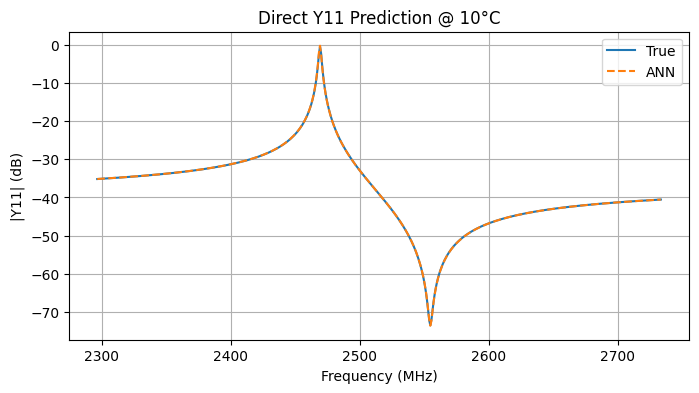


T = 37 °C
Curve MSE = 0.003943


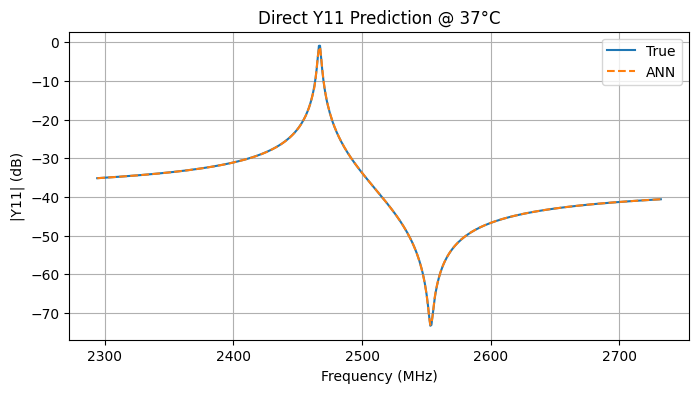


T = 55 °C
Curve MSE = 0.002360


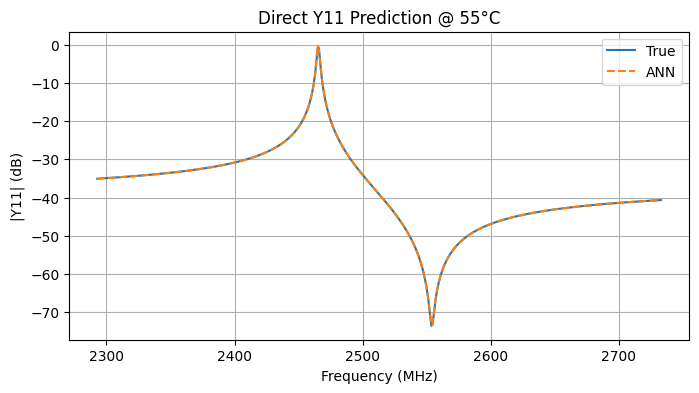


T = 70 °C
Curve MSE = 0.014322


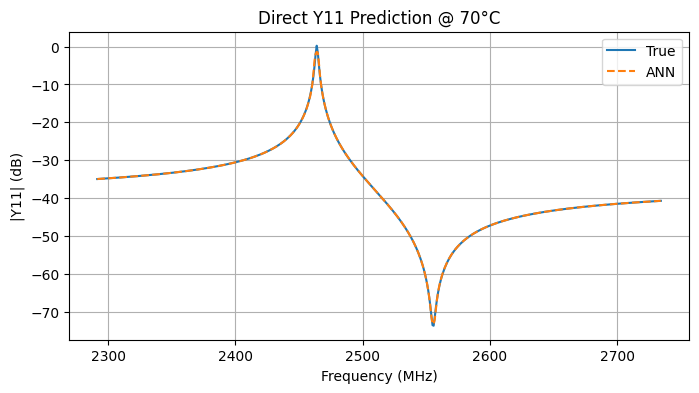


T = 95 °C
Curve MSE = 0.010978


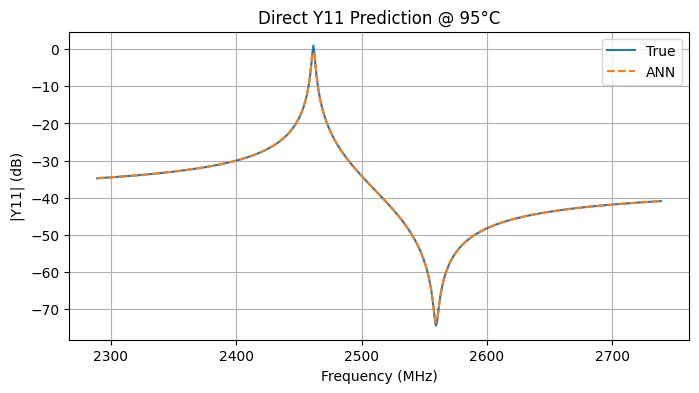

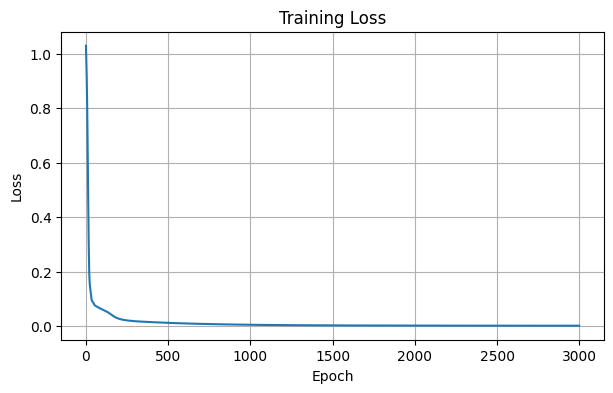

In [ ]:
#direct admittance with new formula
import os
import random
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

tf.get_logger().setLevel("ERROR")

# ======================================================
# FIXED SEEDS
# ======================================================
SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

# ======================================================
# CONSTANTS
# ======================================================
PI = math.pi

# ======================================================
# FIXED MBVD PARAMETERS
# ======================================================
Cs = 7.95e-13

R0 = 0.25

# ======================================================
# BASE PARAMETERS
# ======================================================
fr0 = 2.468e9

Qs0 = 887

Qp0 = 3770

k20 = 0.08

# ======================================================
# THERMAL MODEL PARAMETERS
# ======================================================
TCF1 = -35e-6
TCF2 = -4e-8
TCF3 = 2e-10

alpha1 = 5e-4
alpha2 = 2e-5

beta1 = 0.02
beta2 = 1e-4

gamma1 = 0.015
gamma2 = 8e-5

# ======================================================
# TRUE NONLINEAR THERMAL MODEL
# ======================================================
def true_ECPs(T):

    dT = T - 25.0

    # --------------------------------------------------
    # RESONANCE FREQUENCY
    # --------------------------------------------------
    fr = fr0 * (

        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3

    )

    # --------------------------------------------------
    # ELECTROMECHANICAL COUPLING
    # --------------------------------------------------
    k2 = k20 * (

        1
        + alpha1*dT
        + alpha2*dT**2

    )

    # --------------------------------------------------
    # SERIES QUALITY FACTOR
    # --------------------------------------------------
    Qs = Qs0 * np.exp(

        -beta1*dT/100
        + beta2*dT**2/10000

    )

    # --------------------------------------------------
    # PARALLEL QUALITY FACTOR
    # --------------------------------------------------
    Qp = Qp0 * np.exp(

        -gamma1*dT/100
        + gamma2*dT**2/10000

    )

    # --------------------------------------------------
    # ANTI-RESONANCE FREQUENCY
    # --------------------------------------------------
    fa = (

        2*fr

        /

        (
            1
            +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )
        )

    )

    wr = 2*np.pi*fr

    wa = 2*np.pi*fa

    # --------------------------------------------------
    # MOTIONAL CAPACITANCE
    # --------------------------------------------------
    Cm = Cs * (

        (fa/fr)**2 - 1

    )

    # --------------------------------------------------
    # MOTIONAL INDUCTANCE
    # --------------------------------------------------
    Lm = 1 / (

        (2*np.pi*fr)**2 * Cm

    )

    # --------------------------------------------------
    # MOTIONAL RESISTANCE
    # --------------------------------------------------
    Rm = (

        wr * (Lm/Qs)

    ) - R0

    # --------------------------------------------------
    # TEMPERATURE-DEPENDENT Rs
    # --------------------------------------------------
    Rs = (

        wa * (Lm/Qp)

    ) - Rm

    return (

        np.maximum(Rm,1e-6),
        np.maximum(Lm,1e-18),
        np.maximum(Cm,1e-18),
        np.maximum(Rs,1e-6),
        fr,
        fa

    )

# ======================================================
# NONLINEAR MBVD SIMULATION
# ======================================================
def simulate_Y11(Rm,Lm,Cm,Rs,T):

    dT = T - 25.0

    # --------------------------------------------------
    # RECONSTRUCT fr
    # --------------------------------------------------
    fr = fr0 * (

        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3

    )

    # --------------------------------------------------
    # RECONSTRUCT k2
    # --------------------------------------------------
    k2 = k20 * (

        1
        + alpha1*dT
        + alpha2*dT**2

    )

    # --------------------------------------------------
    # RECONSTRUCT fa
    # --------------------------------------------------
    fa = (

        2*fr

        /

        (
            1
            +
            np.sqrt(
                1 - (16*k2)/(PI**2)
            )
        )

    )

    # --------------------------------------------------
    # FREQUENCY SWEEP
    # --------------------------------------------------
    f = np.linspace(

        fr*0.93,
        fa*1.07,
        512

    )

    w = 2*np.pi*f

    # --------------------------------------------------
    # STATIC BRANCH
    # --------------------------------------------------
    Zs = (

        R0
        +
        1/(1j*w*Cs)

    )

    # --------------------------------------------------
    # MOTIONAL BRANCH
    # --------------------------------------------------
    Zm = (

        Rm
        +
        1j*w*Lm
        +
        1/(1j*w*Cm)

    )

    # --------------------------------------------------
    # PARALLEL NETWORK
    # --------------------------------------------------
    Zp = 1/(1/Zs + 1/Zm)

    # --------------------------------------------------
    # TOTAL IMPEDANCE
    # --------------------------------------------------
    Ztotal = (

        Rs
        +
        Zp

    )

    # --------------------------------------------------
    # ADMITTANCE
    # --------------------------------------------------
    Y11 = np.abs(

        1/Ztotal

    )

    return f,Y11

# ======================================================
# TRAINING DATA
# INPUT  : TEMPERATURE
# OUTPUT : Y11 CURVE
# ======================================================
train_temps = [0,25,60,85,100]

X_train = []

Y_train = []

for T in train_temps:

    # ---------------------------------------------
    # TRUE ECPs
    # ---------------------------------------------
    Rm,Lm,Cm,Rs,_,_ = true_ECPs(T)

    # ---------------------------------------------
    # TRUE Y11
    # ---------------------------------------------
    f,Y11 = simulate_Y11(

        Rm,
        Lm,
        Cm,
        Rs,
        T

    )

    # ---------------------------------------------
    # LOG SCALE
    # ---------------------------------------------
    Y11_db = 20*np.log10(Y11)

    # ---------------------------------------------
    # STORE
    # ---------------------------------------------
    X_train.append([T])

    Y_train.append(Y11_db)

X_train = np.array(X_train,np.float32)

Y_train = np.array(Y_train,np.float32)

# ======================================================
# NORMALIZATION
# ======================================================
Xm = X_train.mean(0)

Xs = X_train.std(0)

Ym = Y_train.mean(0)

Ys = Y_train.std(0)

Xs = np.maximum(Xs,1e-6)

Ys = np.maximum(Ys,1e-6)

Xn = (X_train-Xm)/Xs

Yn = (Y_train-Ym)/Ys

# ======================================================
# ANN MODEL
# DIRECT Y11 PREDICTION
# ======================================================
tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(SEED)

model = tf.keras.Sequential([

    tf.keras.layers.Input((1,)),

    tf.keras.layers.Dense(
        128,
        activation="tanh",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    ),

    tf.keras.layers.Dense(
        128,
        activation="tanh",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    ),

    tf.keras.layers.Dense(
        64,
        activation="tanh",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    ),

    # --------------------------------------------------
    # OUTPUT = FULL Y11 CURVE
    # --------------------------------------------------
    tf.keras.layers.Dense(
        Y_train.shape[1]
    )

])

model.compile(

    optimizer=tf.keras.optimizers.Adam(1e-3),

    loss="mse"

)

earlystop = tf.keras.callbacks.EarlyStopping(

    monitor="loss",

    patience=100,

    restore_best_weights=True

)

history = model.fit(

    Xn,
    Yn,

    epochs=3000,

    verbose=0,

    shuffle=False,

    callbacks=[earlystop]

)

# ======================================================
# TEST TEMPERATURES
# ======================================================
test_temps = [10,37,55,70,95]

print("\n============= DIRECT Y11 PREDICTION =============")

for T in test_temps:

    # --------------------------------------------------
    # TRUE RESPONSE
    # --------------------------------------------------
    Rm,Lm,Cm,Rs,fr,fa = true_ECPs(T)

    f,Y_true = simulate_Y11(

        Rm,
        Lm,
        Cm,
        Rs,
        T

    )

    Y_true_db = 20*np.log10(Y_true)

    # --------------------------------------------------
    # ANN PREDICTION
    # --------------------------------------------------
    Xt = (

        np.array([[T]],dtype=np.float32)

        - Xm

    ) / Xs

    Yp = model.predict(

        Xt,
        verbose=0

    )[0]

    Y_pred_db = (

        Yp * Ys

        + Ym

    )

    # --------------------------------------------------
    # MSE
    # --------------------------------------------------
    mse = np.mean(

        (Y_true_db - Y_pred_db)**2

    )

    print(f"\nT = {T} °C")

    print(f"Curve MSE = {mse:.6f}")

    # --------------------------------------------------
    # PLOT
    # --------------------------------------------------
    plt.figure(figsize=(8,4))

    plt.plot(

        f/1e6,
        Y_true_db,

        label="True"

    )

    plt.plot(

        f/1e6,
        Y_pred_db,

        "--",

        label="ANN"

    )

    plt.xlabel("Frequency (MHz)")

    plt.ylabel("|Y11| (dB)")

    plt.title(f"Direct Y11 Prediction @ {T}°C")

    plt.grid(True)

    plt.legend()

    plt.show()

# ======================================================
# TRAINING LOSS
# ======================================================
plt.figure(figsize=(7,4))

plt.plot(history.history["loss"])

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training Loss")

plt.grid(True)

plt.show()

LOOCV 1/22
LOOCV 2/22
LOOCV 3/22
LOOCV 4/22
LOOCV 5/22
LOOCV 6/22
LOOCV 7/22
LOOCV 8/22
LOOCV 9/22
LOOCV 10/22
LOOCV 11/22
LOOCV 12/22
LOOCV 13/22
LOOCV 14/22
LOOCV 15/22
LOOCV 16/22
LOOCV 17/22
LOOCV 18/22
LOOCV 19/22
LOOCV 20/22
LOOCV 21/22
LOOCV 22/22

FULL NONLINEAR THERMAL MULTI-RESONATOR RESULTS
Mean Curve MSE: 20.900756874332238
Mean Resonance Error (MHz): 1.4751331434065056
Mean Anti-Resonance Error (MHz): 1.244777697646195


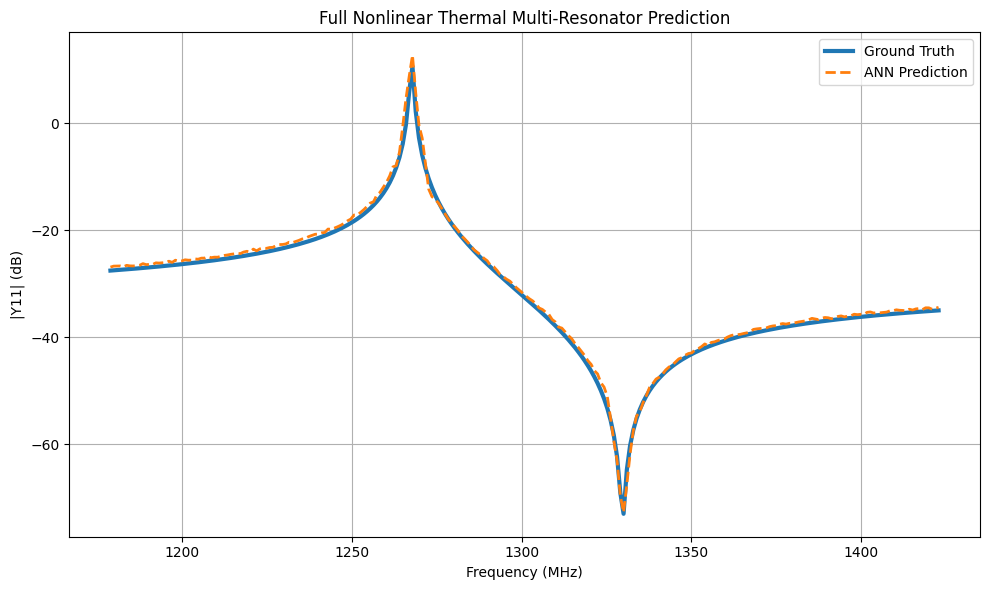

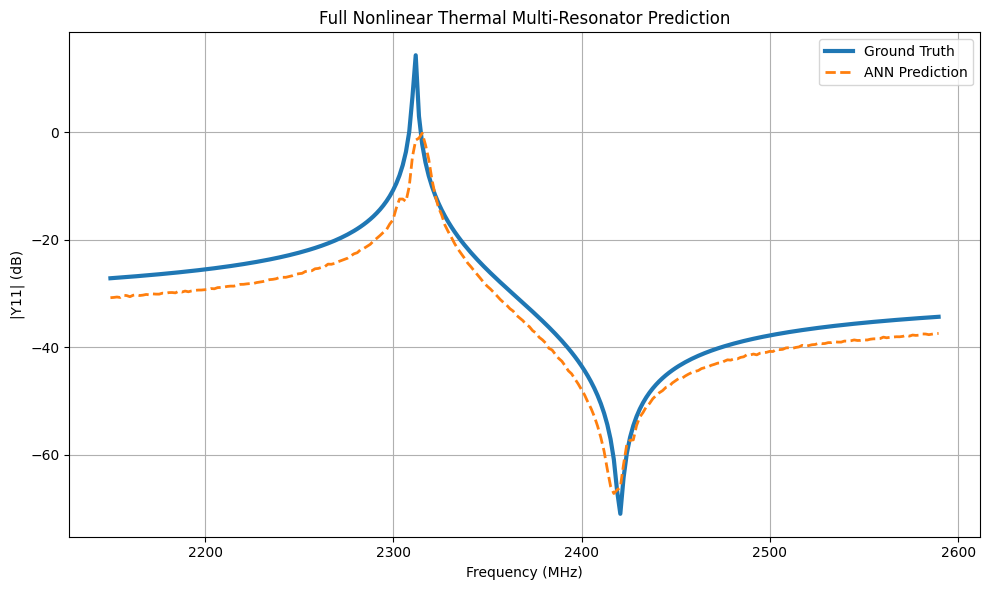

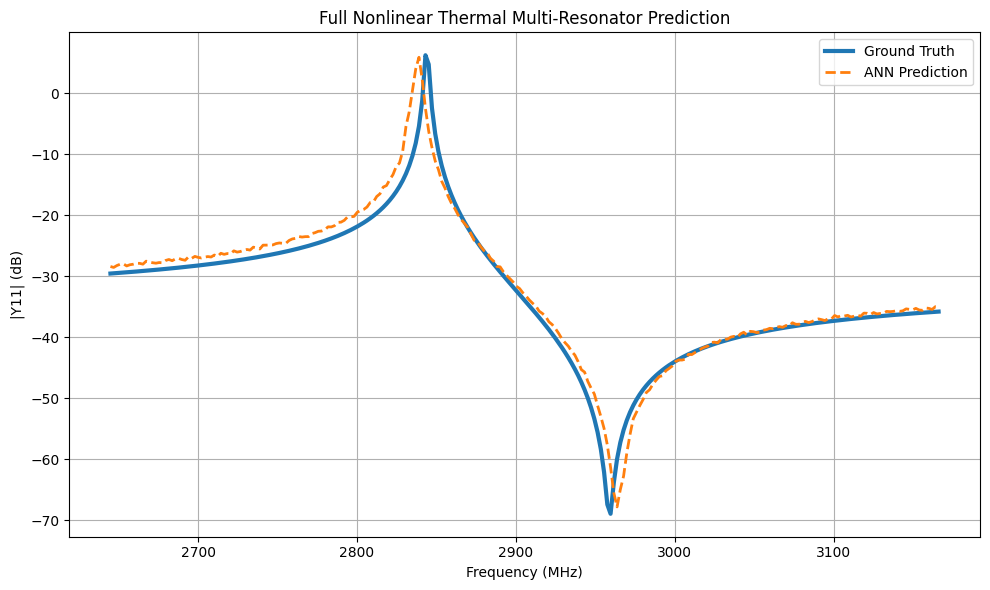

In [ ]:
#multi resonators with new formulation
# =========================================================
# THERMAL MULTI-RESONATOR DIRECT Y11 SURROGATE
# FULL NONLINEAR THERMAL MBVD FORMULATION
#
# INPUT:
# (T, fr0, fa0, Cs, Qs0, Qp0)
#
# OUTPUT:
# Y11(f)
#
# NOW WITH:
# Qp(T)
# Rs(T)
# NON-FIXED ANTI-RESONANCE LOSSES
# =========================================================

import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# =========================================================
# REPRODUCIBILITY
# =========================================================
SEED = 0

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)

np.random.seed(SEED)

tf.keras.utils.set_random_seed(SEED)

tf.config.experimental.enable_op_determinism()

tf.get_logger().setLevel("ERROR")

# =========================================================
# CONSTANTS
# =========================================================
PI = np.pi

N_FREQ = 256

# =========================================================
# FIXED STATIC PARASITIC
# =========================================================
R0_FIXED = 0.25

# =========================================================
# REAL RESONATORS
# =========================================================
# NOW INCLUDING:
# Qp
# =========================================================
real_resonators = [

{"Cs":7.95e-13,"fr":2468e6,"fa":2577e6,"Qs":887,"Qp":3770},
{"Cs":5.989e-13,"fr":2466e6,"fa":2576e6,"Qs":1034,"Qp":1379},
{"Cs":3.981e-13,"fr":2468e6,"fa":2578e6,"Qs":1994,"Qp":1052},
{"Cs":1.857e-12,"fr":2461e6,"fa":2565e6,"Qs":935,"Qp":2513},
{"Cs":1.39e-12,"fr":2488e6,"fa":2597e6,"Qs":804,"Qp":1732},
{"Cs":1.65e-12,"fr":2324e6,"fa":2435e6,"Qs":1038,"Qp":1112},
{"Cs":1.70e-12,"fr":2324e6,"fa":2427e6,"Qs":911,"Qp":1683},
{"Cs":2.60e-12,"fr":1298e6,"fa":1362e6,"Qs":1470,"Qp":2580},
{"Cs":2.03e-12,"fr":1487e6,"fa":1564e6,"Qs":1249,"Qp":1966},
{"Cs":2.36e-12,"fr":1477e6,"fa":1553e6,"Qs":904,"Qp":1153},
{"Cs":1.096e-12,"fr":1722e6,"fa":1806e6,"Qs":2688,"Qp":3530},
{"Cs":3.01e-12,"fr":1443e6,"fa":1512e6,"Qs":1353,"Qp":1585},
{"Cs":3.244e-12,"fr":1269e6,"fa":1329e6,"Qs":1643,"Qp":1645},
{"Cs":1.242e-12,"fr":2847e6,"fa":2958e6,"Qs":906,"Qp":2170},
{"Cs":1.592e-12,"fr":2467e6,"fa":2576e6,"Qs":832,"Qp":2911},
{"Cs":1.90e-12,"fr":2314e6,"fa":2419e6,"Qs":1181,"Qp":2603},
{"Cs":2.132e-12,"fr":2074e6,"fa":2172e6,"Qs":892,"Qp":3792},
{"Cs":2.47e-12,"fr":1719e6,"fa":1800e6,"Qs":974,"Qp":4742},
{"Cs":1.07e-12,"fr":1723e6,"fa":1807e6,"Qs":2291,"Qp":1939},
{"Cs":2.02e-12,"fr":1485e6,"fa":1559e6,"Qs":1089,"Qp":6853},
{"Cs":1.57e-12,"fr":2467e6,"fa":2579e6,"Qs":1095,"Qp":1312},
{"Cs":1.58e-12,"fr":2092e6,"fa":2194e6,"Qs":857,"Qp":1712}

]

# =========================================================
# THERMAL MODEL
# =========================================================
TCF1 = -35e-6
TCF2 = -4e-8
TCF3 = 2e-10

alpha1 = 5e-4
alpha2 = 2e-5

beta1 = 0.02
beta2 = 1e-4

gamma1 = 0.015
gamma2 = 8e-5

# =========================================================
# FULL NONLINEAR THERMAL MBVD MODEL
# =========================================================
def thermal_mbvd(res,T):

    dT = T - 25

    fr0 = res["fr"]

    fa0 = res["fa"]

    Cs = res["Cs"]

    Qs0 = res["Qs"]

    Qp0 = res["Qp"]

    # =====================================================
    # TEMPERATURE-DEPENDENT fr
    # =====================================================
    fr = fr0 * (

        1
        + TCF1*dT
        + TCF2*dT**2
        + TCF3*dT**3
    )

    # =====================================================
    # k2 FROM fr/fa
    # =====================================================
    k2_0 = (

        (PI**2)/16

        *

        (

            1

            -

            ((2*fr0/fa0)-1)**2

        )
    )

    # =====================================================
    # TEMPERATURE-DEPENDENT k2
    # =====================================================
    k2 = k2_0 * (

        1
        + alpha1*dT
        + alpha2*dT**2
    )

    # =====================================================
    # TEMPERATURE-DEPENDENT Qs
    # =====================================================
    Qs = Qs0 * np.exp(

        -beta1*dT/100

        + beta2*dT**2/10000
    )

    # =====================================================
    # TEMPERATURE-DEPENDENT Qp
    # =====================================================
    Qp = Qp0 * np.exp(

        -gamma1*dT/100

        + gamma2*dT**2/10000
    )

    # =====================================================
    # TEMPERATURE-DEPENDENT fa
    # =====================================================
    fa = (

        2*fr

        /

        (

            1

            +

            np.sqrt(

                1 - 16*k2/(PI**2)

            )
        )
    )

    wr = 2*PI*fr

    wa = 2*PI*fa

    # =====================================================
    # MBVD PARAMETERS
    # =====================================================
    Cm = Cs*((fa/fr)**2 -1)

    Lm = 1/((2*PI*fr)**2 * Cm)

    # =====================================================
    # Rm
    # =====================================================
    Rm = (

        wr * (Lm/Qs)

    ) - R0_FIXED

    # =====================================================
    # TEMPERATURE-DEPENDENT Rs
    # =====================================================
    Rs = (

        wa * (Lm/Qp)

    ) - Rm

    # =====================================================
    # SAFETY
    # =====================================================
    Rm = np.maximum(Rm,1e-6)

    Rs = np.maximum(Rs,1e-6)

    return Rm,Lm,Cm,Cs,Rs,fr,fa

# =========================================================
# COMPUTE Y11
# =========================================================
def compute_Y11(res,T):

    Rm,Lm,Cm,Cs,Rs,fr,fa = thermal_mbvd(res,T)

    f = np.linspace(

        fr*0.93,

        fa*1.07,

        N_FREQ
    )

    w = 2*PI*f

    # =====================================================
    # STATIC BRANCH
    # =====================================================
    Zs = (

        R0_FIXED

        +

        1/(1j*w*Cs)
    )

    # =====================================================
    # MOTIONAL BRANCH
    # =====================================================
    Zm = (

        Rm

        + 1/(1j*w*Cm)

        + 1j*w*Lm
    )

    # =====================================================
    # PARALLEL NETWORK
    # =====================================================
    Zp = 1/(1/Zs + 1/Zm)

    # =====================================================
    # TOTAL IMPEDANCE
    # =====================================================
    Ztotal = Rs + Zp

    # =====================================================
    # ADMITTANCE
    # =====================================================
    Y11 = np.abs(1/Ztotal)

    return Y11,f

# =========================================================
# BUILD MODEL
# =========================================================
def build_model():

    tf.keras.backend.clear_session()

    model = tf.keras.Sequential([

        # =================================================
        # INPUT:
        # (T, fr0, fa0, Cs, Qs0, Qp0)
        # =================================================
        tf.keras.layers.Input((6,)),

        tf.keras.layers.Dense(
            128,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dense(
            128,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dense(
            64,
            activation="tanh",
            kernel_regularizer=tf.keras.regularizers.l2(1e-4)
        ),

        # =================================================
        # OUTPUT:
        # FULL Y11 CURVE
        # =================================================
        tf.keras.layers.Dense(N_FREQ)

    ])

    model.compile(

        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),

        loss="mse"
    )

    return model

# =========================================================
# RESULTS STORAGE
# =========================================================
curve_mse = []

res_errors = []

anti_errors = []

example_results = []

# =========================================================
# TRAINING TEMPERATURES
# =========================================================
train_temps = [0,25,60,85,100]

# =========================================================
# TEST TEMPERATURES
# =========================================================
test_temps = [10,37,55,70,95]

# =========================================================
# LOOCV OVER RESONATORS
# =========================================================
for i in range(len(real_resonators)):

    print(f"LOOCV {i+1}/{len(real_resonators)}")

    # =====================================================
    # TEST RESONATOR
    # =====================================================
    test_res = real_resonators[i]

    # =====================================================
    # TRAIN RESONATORS
    # =====================================================
    train_res = (

        real_resonators[:i]

        +

        real_resonators[i+1:]

    )

    X_train = []

    Y_train = []

    # =====================================================
    # BUILD TRAINING DATASET
    # =====================================================
    for r in train_res:

        for T in train_temps:

            Y11,f = compute_Y11(r,T)

            Y11_db = 20*np.log10(Y11 + 1e-15)

            X_train.append([

                T,
                r["fr"],
                r["fa"],
                r["Cs"],
                r["Qs"],
                r["Qp"]

            ])

            Y_train.append(Y11_db)

    X_train = np.array(X_train,np.float32)

    Y_train = np.array(Y_train,np.float32)

    # =====================================================
    # NORMALIZATION
    # =====================================================
    Xm = X_train.mean(0)

    Xs = X_train.std(0)

    Ym = Y_train.mean(0)

    Ys = Y_train.std(0)

    Xs = np.where(Xs < 1e-12,1.0,Xs)

    Ys = np.where(Ys < 1e-12,1.0,Ys)

    Xn = (X_train - Xm)/Xs

    Yn = (Y_train - Ym)/Ys

    # =====================================================
    # MODEL
    # =====================================================
    model = build_model()

    earlystop = tf.keras.callbacks.EarlyStopping(

        monitor="loss",

        patience=50,

        restore_best_weights=True
    )

    # =====================================================
    # TRAINING
    # =====================================================
    model.fit(

        Xn,
        Yn,

        epochs=1000,

        batch_size=16,

        verbose=0,

        shuffle=True,

        callbacks=[earlystop]
    )

    # =====================================================
    # TEST TEMPERATURES
    # =====================================================
    for T in test_temps:

        # =================================================
        # GROUND TRUTH
        # =================================================
        Y_true,f = compute_Y11(test_res,T)

        Y_true_db = 20*np.log10(Y_true + 1e-15)

        # =================================================
        # TEST INPUT
        # =================================================
        Xt = np.array([[

            T,
            test_res["fr"],
            test_res["fa"],
            test_res["Cs"],
            test_res["Qs"],
            test_res["Qp"]

        ]],dtype=np.float32)

        Xt = (Xt - Xm)/Xs

        # =================================================
        # PREDICTION
        # =================================================
        Y_pred = model.predict(
            Xt,
            verbose=0
        )[0]

        Y_pred = Y_pred*Ys + Ym

        # =================================================
        # METRICS
        # =================================================
        mse = np.mean(

            (Y_true_db - Y_pred)**2
        )

        curve_mse.append(mse)

        # =================================================
        # RESONANCE EXTRACTION
        # =================================================
        fr_true = f[np.argmax(Y_true_db)]

        fr_pred = f[np.argmax(Y_pred)]

        fa_true = f[np.argmin(Y_true_db)]

        fa_pred = f[np.argmin(Y_pred)]

        res_errors.append(

            abs(fr_true-fr_pred)/1e6
        )

        anti_errors.append(

            abs(fa_true-fa_pred)/1e6
        )

        # =================================================
        # STORE EXAMPLES
        # =================================================
        if T == 55:

            example_results.append({

                "f":f,

                "Y_true":Y_true_db,

                "Y_pred":Y_pred,

                "fr":test_res["fr"]

            })

# =========================================================
# FINAL RESULTS
# =========================================================
print("\n========================================")

print("FULL NONLINEAR THERMAL MULTI-RESONATOR RESULTS")

print("========================================")

print("Mean Curve MSE:",
      np.mean(curve_mse))

print("Mean Resonance Error (MHz):",
      np.mean(res_errors))

print("Mean Anti-Resonance Error (MHz):",
      np.mean(anti_errors))

# =========================================================
# SORT EXAMPLES
# =========================================================
example_results.sort(
    key=lambda x: x["fr"]
)

# =========================================================
# REPRESENTATIVE PLOTS
# =========================================================
indices = [

    0,

    len(example_results)//2,

    -1
]

for idx in indices:

    ex = example_results[idx]

    plt.figure(figsize=(10,6))

    plt.plot(

        ex["f"]/1e6,

        ex["Y_true"],

        linewidth=3,

        label="Ground Truth"
    )

    plt.plot(

        ex["f"]/1e6,

        ex["Y_pred"],

        "--",

        linewidth=2,

        label="ANN Prediction"
    )

    plt.xlabel("Frequency (MHz)")

    plt.ylabel("|Y11| (dB)")

    plt.title(
        "Full Nonlinear Thermal Multi-Resonator Prediction"
    )

    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()